**AICE Associate <font color=red>사례실습</font> — 미세먼지 수치 예측 ② 모델링**

### <span style="color:darkgreen">**대기오염 물질 농도와 시간 정보로 미세먼지(PM10) 수치 예측하기 — 회귀 문제**</span>
---

- 도메인 : 환경
- 목  표 : 16-①에서 만든 `air_preprocessed.csv`로 PM10 수치를 예측하는 머신러닝·딥러닝 **회귀** 모델을 만들고 비교합니다.

### 회귀 문제 핵심 정리
| 구분 | 분류 | **회귀** |
|---|---|---|
| 타깃 | 범주 (0/1, Y/N) | **연속된 숫자** (PM10 ㎍/㎥) |
| 모델 | ~Classifier | **~Regressor**, LinearRegression |
| 평가 | accuracy, f1 | **MAE, MSE, RMSE, R²** |
| stratify | 사용 | **사용하지 않음** |
| 딥러닝 출력층 | sigmoid / softmax | **Dense(1, activation='linear')** |
| 딥러닝 loss | binary_crossentropy | **mse (mean_squared_error)** |

> **다음 문항을 풀기 전에 <span style="color:red">아래 코드를 실행하세요.</span>**

In [1]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


In [2]:
# [준비] air_preprocessed.csv 가 없으면 16-① 전처리를 자동으로 수행합니다. (그대로 실행)
import os, glob
if not os.path.exists('air_preprocessed.csv'):
    air = pd.concat([pd.read_csv(f, encoding='cp949') for f in sorted(glob.glob('air_data_*.csv'))], ignore_index=True)
    air['일시'] = pd.to_datetime((air['측정일시'] // 100).astype(str), format='%Y%m%d') + pd.to_timedelta(air['측정일시'] % 100, unit='h')
    air = air.drop(['지역', '망', '측정소코드', '주소', '측정일시'], axis=1)
    air = air.dropna(subset=['PM10']).sort_values(['측정소명', '일시']).reset_index(drop=True)
    cols = ['SO2', 'CO', 'O3', 'NO2', 'PM25']
    air[cols] = air.groupby('측정소명')[cols].transform(lambda s: s.interpolate().bfill().ffill())
    air = air[air['PM10'] < 900].reset_index(drop=True)
    air['month'], air['day'], air['hour'], air['weekday'] = air['일시'].dt.month, air['일시'].dt.day, air['일시'].dt.hour, air['일시'].dt.weekday
    air['season'] = air['month'].map({3: '봄', 4: '봄', 5: '봄', 6: '여름', 7: '여름', 8: '여름', 9: '가을', 10: '가을', 11: '가을', 12: '겨울', 1: '겨울', 2: '겨울'})
    air['PM10_grade'] = pd.cut(air['PM10'], bins=[-1, 30, 80, 150, 10000], labels=['좋음', '보통', '나쁨', '매우나쁨'])
    air.to_csv('air_preprocessed.csv', index=False, encoding='utf-8-sig')
    print('air_preprocessed.csv 생성 완료')
else:
    print('air_preprocessed.csv 가 이미 있습니다')

air_preprocessed.csv 가 이미 있습니다


<br>

## <font color=blue>**<데이터 준비>**</font>

### **1. air_preprocessed.csv를 읽어 df에 저장하고, 일시 컬럼을 datetime 형식으로 바꾸세요.**
---

In [3]:
# [1번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [4]:
# [1번 정답]
df = pd.read_csv('air_preprocessed.csv')
df['일시'] = pd.to_datetime(df['일시'])
print(df.shape)
df.head(3)

(197327, 14)


,측정소명,SO2,CO,O3,NO2,PM10,PM25,일시,month,day,hour,weekday,season,PM10_grade
0,강남구,0.0039,0.4,0.0090,0.0216,53.0,28.0,2025-01-01 01:00:00,1,1,1,2,겨울,보통
1,강남구,0.0036,0.5,0.0081,0.0253,37.0,20.0,2025-01-01 02:00:00,1,1,2,2,겨울,보통
2,강남구,0.0024,0.5,0.0057,0.0164,35.0,19.0,2025-01-01 03:00:00,1,1,3,2,겨울,보통


<br>

### **2. 모델 입력 데이터를 만드세요.**
---
- 모델링에 사용하지 않을 컬럼 '일시', 'day', 'PM10_grade'를 삭제하세요. (PM10_grade는 정답(PM10)에서 만든 컬럼이라 넣으면 **정답 유출**)
- '측정소명', 'season'을 원-핫 인코딩하세요. (dtype=int)
- 결과를 df_preset에 저장하고 컬럼 개수를 '답안2'에 저장하세요.
---

In [5]:
# [2번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [6]:
# [2번 정답]
df_preset = df.drop(['일시', 'day', 'PM10_grade'], axis=1)
df_preset = pd.get_dummies(df_preset, columns=['측정소명', 'season'], dtype=int)
print(df_preset.shape)
답안2 = df_preset.shape[1]
print('답안2 =', 답안2)

(197327, 38)
답안2 = 38


<br>

### **3. PM10을 레이블 y로, 나머지를 피처 X로 하여 데이터를 분리하고 스케일링하세요.**
---
- 훈련:검증 = 80:20, 난수 시드 42 (회귀이므로 stratify 없음)
- StandardScaler를 ss 변수에 지정하고, X_train은 fit_transform, X_valid는 transform
- 아래 코드의 오류를 정정하세요.
---

In [7]:
# [3번 문항] 아래의 코드를 정정하고 실행하세요.
# X = df_preset.drop('PM10')
# y = df_preset['PM10']
# X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.8, random_state=42, stratify=y)
#
# ss = StandardScaler()
# X_train = ss.fit_transform(X_train)
# X_valid = ss.fit_transform(X_valid)

In [8]:
# [3번 정답]
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_preset.drop('PM10', axis=1)
y = df_preset['PM10']
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)
print(X_train.shape, X_valid.shape)

(157861, 37) (39466, 37)


<br>

## <font color=blue>**<머신러닝 모델링>**</font>

### **4. 선형회귀, 의사결정나무, 랜덤포레스트 회귀 모델을 학습하세요.**
---
- LinearRegression → lr
- DecisionTreeRegressor(max_depth=10, random_state=42) → dt
- RandomForestRegressor(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42) → rf
- 각 모델로 검증데이터를 예측해 y_pred_lr, y_pred_dt, y_pred_rf에 저장하세요.
---

In [9]:
# [4번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [10]:
# [4번 정답]
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_valid)

dt = DecisionTreeRegressor(max_depth=10, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_valid)

rf = RandomForestRegressor(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_valid)
print('학습 완료')

학습 완료


<br>

### **5. 회귀 평가지표로 세 모델을 비교하세요.**
---
- MAE, MSE, RMSE, R² 를 계산해 result 데이터프레임으로 만들고 출력하세요.
- **MAE가 가장 낮은** 모델 이름을 '답안5_1'에, 그 모델의 R²를 소수점 셋째 자리까지 반올림해 '답안5_2'에 저장하세요.
- 코드의 빈칸을 채우고 빈칸 내용을 '답안5_3', '답안5_4'에 저장하세요.
---

In [11]:
# [5번 문항] 아래 코드의 빈칸을 채우고 실행하세요.
# from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#
# rows = []
# for name, p in [('LinearRegression', y_pred_lr), ('DecisionTree', y_pred_dt), ('RandomForest', y_pred_rf)]:
#     mse = mean_squared_error(y_valid, p)
#     rows.append({'model': name,
#                  'MAE': < blank5-1 >(y_valid, p),
#                  'MSE': mse,
#                  'RMSE': np.< blank5-2 >(mse),
#                  'R2': r2_score(y_valid, p)})
# result = pd.DataFrame(rows)
# result

In [12]:
# [5번 정답]
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rows = []
for name, p in [('LinearRegression', y_pred_lr), ('DecisionTree', y_pred_dt), ('RandomForest', y_pred_rf)]:
    mse = mean_squared_error(y_valid, p)
    rows.append({'model': name,
                 'MAE': mean_absolute_error(y_valid, p),
                 'MSE': mse,
                 'RMSE': np.sqrt(mse),
                 'R2': r2_score(y_valid, p)})
result = pd.DataFrame(rows)
display(result.round(3))

best = result.sort_values('MAE').iloc[0]
답안5_1 = best['model']
답안5_2 = round(best['R2'], 3)
답안5_3 = 'mean_absolute_error'
답안5_4 = 'sqrt'
print(답안5_1, 답안5_2)

,model,MAE,MSE,RMSE,R2
0,LinearRegression,7.192,135.303,11.632,0.898
1,DecisionTree,4.176,32.931,5.739,0.975
2,RandomForest,4.030,28.478,5.336,0.979


RandomForest 0.979


<br>

### **6. 랜덤포레스트의 변수 중요도 상위 10개를 시각화하세요.**
---
- 가장 중요한 변수명을 '답안6'에 저장하세요.
---

In [13]:
# [6번 문항] 여기에 답안코드를 작성하고 실행하세요.

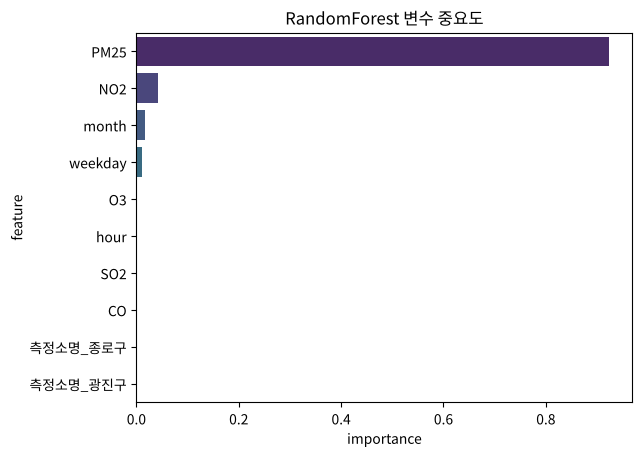

답안6 = PM25


In [14]:
# [6번 정답]
fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi, palette='viridis')
plt.title('RandomForest 변수 중요도')
plt.show()

답안6 = fi.iloc[0]['feature']
print('답안6 =', 답안6)

<br>

### **7. 예측 결과를 시각화하세요.**
---
- 왼쪽: 실제값(x) vs 랜덤포레스트 예측값(y) 산점도 + 대각선(y=x)
- 오른쪽: 검증데이터 중 첫 200개의 실제값과 예측값을 선 그래프로 비교 (범례 ['actual', 'pred'])
---

In [15]:
# [7번 문항] 여기에 답안코드를 작성하고 실행하세요.

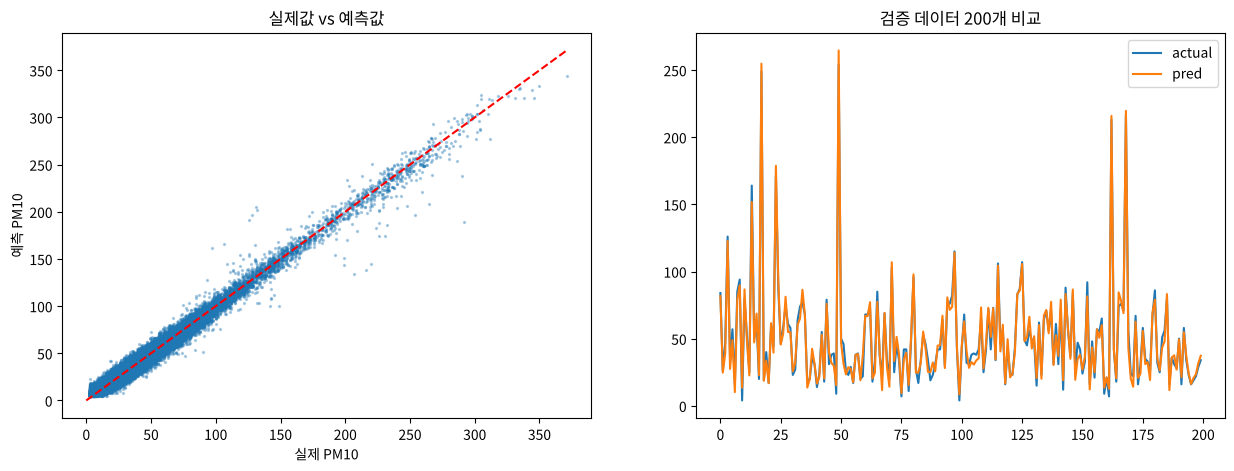

In [16]:
# [7번 정답]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(y_valid, y_pred_rf, s=2, alpha=0.3)
axes[0].plot([0, y_valid.max()], [0, y_valid.max()], 'r--')
axes[0].set_xlabel('실제 PM10')
axes[0].set_ylabel('예측 PM10')
axes[0].set_title('실제값 vs 예측값')

axes[1].plot(y_valid.values[:200])
axes[1].plot(y_pred_rf[:200])
axes[1].legend(['actual', 'pred'])
axes[1].set_title('검증 데이터 200개 비교')
plt.show()

<br>

## <font color=blue>**<딥러닝 모델링>**</font>

> **딥러닝 모델을 구현하기 위해 <span style="color:red">아래 코드를 실행하세요.</span>**

In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

### **8. PM10을 예측하는 딥러닝 회귀 모델을 만들고 학습하세요.**
---
- 토폴로지 : Dense(128, relu, 입력) → Dropout(0.2) → Dense(64, relu) → Dense(32, relu) → Dense(1, linear)
- 모델 변수명 : model
- EarlyStopping(monitor='val_loss', patience=5) → estop
- optimizer='adam', loss='mse', metrics=['mae']
- epochs=30, batch_size=256, validation_data=(X_valid, y_valid), callbacks=[estop]
- 학습 정보는 history에 저장하세요.
---

In [18]:
# [8번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [19]:
# [8번 정답]
model = Sequential()
model.add(Dense(128, activation='relu', input_dim=X_train.shape[1]))
model.add(Dropout(0.2))
model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='linear'))

estop = EarlyStopping(monitor='val_loss', patience=5)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train, epochs=30, batch_size=256,
                    validation_data=(X_valid, y_valid), callbacks=[estop], verbose=2)

Epoch 1/30


617/617 - 3s - 5ms/step - loss: 436.0323 - mae: 11.1194 - val_loss: 72.3281 - val_mae: 5.4180


Epoch 2/30


617/617 - 2s - 3ms/step - loss: 84.3887 - mae: 6.0870 - val_loss: 57.0853 - val_mae: 4.9088


Epoch 3/30


...

617/617 - 2s - 3ms/step - loss: 38.6036 - mae: 4.4507 - val_loss: 34.2595 - val_mae: 4.3229


Epoch 29/30


617/617 - 2s - 3ms/step - loss: 38.4666 - mae: 4.4347 - val_loss: 34.9753 - val_mae: 4.3954


Epoch 30/30


617/617 - 2s - 3ms/step - loss: 38.1734 - mae: 4.4256 - val_loss: 37.3637 - val_mae: 4.5279


<br>

### **9. 학습 MAE와 검증 MAE의 변화를 시각화하세요.**
---
- 범례 'mae', 'val_mae' / 제목 'Model MAE' / X축 'Epoch' / Y축 'MAE'
---

In [20]:
# [9번 문항] 여기에 답안코드를 작성하고 실행하세요.

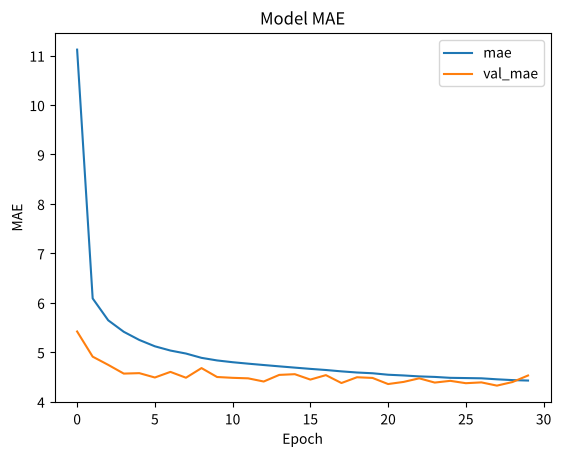

In [21]:
# [9번 정답]
plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('Model MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend(['mae', 'val_mae'])
plt.show()

<br>

### **10. 딥러닝 모델을 평가하고 머신러닝 결과와 비교하세요.**
---
- 검증데이터 예측값을 y_pred_dl에 저장하세요. (predict 결과는 2차원 → ravel()로 1차원)
- MAE, RMSE, R²를 출력하고 result에 'DeepLearning' 행을 추가하세요.
- 전체 모델 중 R²가 가장 높은 모델명을 '답안10'에 저장하세요.
---

In [22]:
# [10번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [23]:
# [10번 정답]
y_pred_dl = model.predict(X_valid, verbose=0).ravel()
mse = mean_squared_error(y_valid, y_pred_dl)
dl_row = {'model': 'DeepLearning', 'MAE': mean_absolute_error(y_valid, y_pred_dl),
          'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y_valid, y_pred_dl)}
result_all = pd.concat([result, pd.DataFrame([dl_row])], ignore_index=True)
display(result_all.round(3))

답안10 = result_all.sort_values('R2', ascending=False).iloc[0]['model']
print('답안10 =', 답안10)

,model,MAE,MSE,RMSE,R2
0,LinearRegression,7.192,135.303,11.632,0.898
1,DecisionTree,4.176,32.931,5.739,0.975
2,RandomForest,4.030,28.478,5.336,0.979
3,DeepLearning,4.528,37.364,6.113,0.972


답안10 = RandomForest


<br>

## <font color=blue>**<심화: 실무 관점에서 다시 보기>**</font>

### **11. PM25(초미세먼지)를 빼면 성능이 어떻게 될까요?**
---
PM25는 PM10과 상관계수가 0.9 이상이라 예측이 쉬워집니다. 하지만 **실제로 PM10을 예측해야 하는 상황에서는 같은 시각의 PM25도 모르는 경우가 많습니다.**
PM25를 제외하고 RandomForest를 다시 학습해 R²를 비교해 보세요.

In [24]:
# [11번] 여기에 코드를 작성하고 실행하세요.

In [25]:
# [11번 예시 코드]
X2 = df_preset.drop(['PM10', 'PM25'], axis=1)
X2_train, X2_valid, y2_train, y2_valid = train_test_split(X2, y, test_size=0.2, random_state=42)
ss2 = StandardScaler()
X2_train = ss2.fit_transform(X2_train)
X2_valid = ss2.transform(X2_valid)

rf2 = RandomForestRegressor(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
rf2.fit(X2_train, y2_train)
p2 = rf2.predict(X2_valid)
print('PM25 포함 R2 :', round(r2_score(y_valid, y_pred_rf), 3))
print('PM25 제외 R2 :', round(r2_score(y2_valid, p2), 3), '/ MAE:', round(mean_absolute_error(y2_valid, p2), 2))

PM25 포함 R2 : 0.979
PM25 제외 R2 : 0.707 / MAE: 10.49


> 💡 **해석**: 입력 변수 하나에 따라 성능이 크게 달라집니다. 모델 성능 숫자만 볼 것이 아니라 **"예측 시점에 이 변수를 정말 알 수 있는가?"** 를 따져야 합니다.

### **12. 시간 순서를 지키는 검증 (Time-based Split)**
---
무작위 분할은 같은 날 같은 시각의 다른 측정소 데이터가 학습/검증에 동시에 들어가 성능이 실제보다 좋아 보일 수 있습니다.
시계열 예측에서는 **과거로 학습하고 미래로 검증**하는 것이 원칙입니다. 1~9월로 학습하고 10~11월로 검증해 보세요.

In [26]:
# [12번 예시 코드]
train_mask = df['month'] <= 9
X3 = df_preset.drop(['PM10', 'PM25'], axis=1)
X3_train, X3_valid = X3[train_mask], X3[~train_mask]
y3_train, y3_valid = y[train_mask], y[~train_mask]

ss3 = StandardScaler()
X3_train = ss3.fit_transform(X3_train)
X3_valid = ss3.transform(X3_valid)

rf3 = RandomForestRegressor(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
rf3.fit(X3_train, y3_train)
p3 = rf3.predict(X3_valid)
print('시간 기준 분할 (PM25 제외) R2:', round(r2_score(y3_valid, p3), 3), '/ MAE:', round(mean_absolute_error(y3_valid, p3), 2))

시간 기준 분할 (PM25 제외) R2: 0.071 / MAE: 15.69


> 💡 학습에 없던 10~11월(계절)이 검증에 들어가면 성능이 떨어지는 것이 자연스럽습니다.
> 실무에서는 기상 정보(풍속, 습도, 강수), 전날/전 시간의 PM10 값(lag 변수) 등을 추가해 성능을 높입니다.
> AICE 시험에서는 **문항 가이드대로 train_test_split** 을 사용하면 됩니다.

<br>

### **🎉 AICE Associate 학습 과정을 모두 마쳤습니다!**
마지막으로 `source` 폴더의 **샘플문항(분류·회귀)** 을 시간(90분)을 재고 풀어 보세요.